In [1]:
# ---------- CELL 0: locate the project (same in every notebook) ----------
import os, sys
from pathlib import Path

def find_root(marker="PROJECT_ROOT.marker"):
    here = Path.cwd().resolve()                      # start where this notebook runs
    for folder in [here, *here.parents]:             # go UP one level at a time
        if (folder / marker).exists():
            return folder
    if "google.colab" in sys.modules:                # Colab: look inside Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        for pattern in (marker, f"*/{marker}", f"*/*/{marker}", f"*/*/*/{marker}"):
            hits = sorted(Path("/content/drive/MyDrive").glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError("PROJECT_ROOT.marker not found - finish Day 1 first.")

ROOT = find_root()
os.chdir(ROOT / "notebooks")
RAW, CLEAN = ROOT/"data"/"raw", ROOT/"data"/"clean"
FEATURES, MODEL_OUT = ROOT/"data"/"features", ROOT/"data"/"model_outputs"
SQL_EXPORTS, BI_READY = ROOT/"data"/"sql_exports", ROOT/"data"/"bi_ready"
MODELS, REPORTS, DOCS = ROOT/"models", ROOT/"reports", ROOT/"docs"
FIGURES = REPORTS/"figures"
sys.path.append(str(ROOT/"src"))
print("Project root:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/Internmo/netflix_churn_project


In [2]:
# ---------- CELL 1: load and define columns ----------
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
warnings.filterwarnings("ignore")

train_table   = pd.read_csv(FEATURES / "customer_features_train.csv")
scoring_table = pd.read_csv(FEATURES / "customer_features_scoring.csv")

TARGET = "churned"
NOT_FEATURES = ["customer_id", "snapshot_date", "active_at_snapshot", TARGET]
CATEGORICAL = ["gender", "customer_segment", "acquisition_channel", "country", "plan_name"]
NUMERIC = [c for c in train_table.columns if c not in NOT_FEATURES + CATEGORICAL]

X = train_table[CATEGORICAL + NUMERIC]
y = train_table[TARGET]
print(len(X), "customers |", len(NUMERIC), "numeric +", len(CATEGORICAL), "categorical features | churn rate", round(100 * y.mean(), 1), "%")

7277 customers | 21 numeric + 5 categorical features | churn rate 24.4 %


In [3]:
# ---------- CELL 2: train / test split ----------
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)       # stratify = same churn share in both parts
ids_test = train_table.loc[X_test.index, "customer_id"]
print("train:", len(X_train), "| test:", len(X_test), "| churn share train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

train: 5821 | test: 1456 | churn share train/test: 0.244 0.245


In [4]:
# ---------- CELL 3: the pipeline recipe ----------
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipeline(model, numeric=NUMERIC, categorical=CATEGORICAL):
    numeric_steps = Pipeline([
        ("fill_blanks", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    prepare = ColumnTransformer([
        ("numbers",    numeric_steps, numeric),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])
    return Pipeline([("prepare", prepare), ("model", model)])

In [5]:
# ---------- CELL 4: compare models ----------
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier

candidates = {
    "Baseline (always guess the average)": DummyClassifier(strategy="prior"),
    "Logistic Regression":                  LogisticRegression(max_iter=2000, C=0.1),
    "Random Forest":                        RandomForestClassifier(n_estimators=300, min_samples_leaf=25, random_state=42, n_jobs=-1),
    "Gradient Boosting":                    GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in candidates.items():
    scores = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="roc_auc")
    rows.append({"model": name, "cv_auc_mean": scores.mean().round(3), "cv_auc_std": scores.std().round(3)})
comparison = pd.DataFrame(rows).sort_values("cv_auc_mean", ascending=False)
comparison

,model,cv_auc_mean,cv_auc_std
3,Gradient Boosting,0.578,0.016
1,Logistic Regression,0.573,0.018
2,Random Forest,0.570,0.016
0,Baseline (always guess the average),0.500,0.000


In [6]:
# ---------- CELL 5: tune the winner (only among real models, not the baseline) ----------
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

real_models = comparison[~comparison["model"].str.startswith("Baseline")]
best_name = real_models.iloc[0]["model"]
print("Best in cross-validation:", best_name)

grids = {
    "Logistic Regression": {"model__C": [0.01, 0.03, 0.1, 0.3, 1]},
    "Random Forest":       {"model__min_samples_leaf": [10, 25, 50], "model__max_depth": [4, 8, None]},
    "Gradient Boosting":   {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.05], "model__max_depth": [2, 3]},
}
search = GridSearchCV(make_pipeline(clone(candidates[best_name])), grids[best_name],
                      cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X_train, y_train)
print("best settings:", search.best_params_)
print("tuned cross-validated AUC:", round(search.best_score_, 3))
best_pipeline = search.best_estimator_

Best in cross-validation: Gradient Boosting
best settings: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100}
tuned cross-validated AUC: 0.578


In [7]:
# ---------- CELL 6: two sanity experiments ----------
# Experiment 1: remove auto_renew (the one feature that might carry a little future information)
no_auto = [c for c in NUMERIC if c != "auto_renew"]
auc_without = cross_val_score(make_pipeline(clone(best_pipeline.named_steps["model"]), numeric=no_auto),
                              X_train.drop(columns="auto_renew"), y_train, cv=cv, scoring="roc_auc").mean()
print(f"AUC with auto_renew   : {search.best_score_:.3f}")
print(f"AUC without auto_renew: {auc_without:.3f}   (about the same = the feature is not driving the result)")

# Experiment 2: the LEAKY version on purpose. Same customers, same model, but features measured on 2026-06-30,
# AFTER many of them had already churned. This is exactly what Day 9 told us not to do.
leaky = scoring_table[scoring_table["customer_id"].isin(train_table["customer_id"])]
auc_leaky = cross_val_score(clone(best_pipeline), leaky[CATEGORICAL + NUMERIC], leaky[TARGET], cv=cv, scoring="roc_auc").mean()
print(f"\nHonest AUC (features at the cutoff)      : {search.best_score_:.3f}")
print(f"Leaky AUC (features measured afterwards) : {auc_leaky:.3f}   <- looks better, but it is cheating")

AUC with auto_renew   : 0.578
AUC without auto_renew: 0.578   (about the same = the feature is not driving the result)

Honest AUC (features at the cutoff)      : 0.578
Leaky AUC (features measured afterwards) : 0.648   <- looks better, but it is cheating


Test AUC               : 0.568   (0.50 = coin flip)
Test average precision : 0.300   (compare with the churn rate 0.245, which is a random guess)


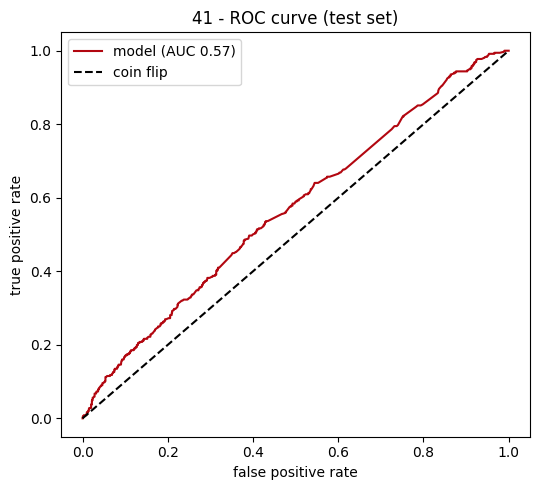

In [8]:
# ---------- CELL 7: evaluate on the test set (once) ----------
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

best_pipeline.fit(X_train, y_train)
test_proba = best_pipeline.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_proba)
test_ap  = average_precision_score(y_test, test_proba)
print(f"Test AUC               : {test_auc:.3f}   (0.50 = coin flip)")
print(f"Test average precision : {test_ap:.3f}   (compare with the churn rate {y_test.mean():.3f}, which is a random guess)")

fpr, tpr, _ = roc_curve(y_test, test_proba)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, color="#b20710", label=f"model (AUC {test_auc:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="coin flip")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate"); plt.title("41 - ROC curve (test set)"); plt.legend()
plt.tight_layout(); plt.savefig(FIGURES / "41_roc_curve.png", bbox_inches="tight"); plt.show()

             customers  churn_rate  lift_vs_average
risk_decile                                        
1                  146       0.137            0.560
2                  146       0.233            0.952
3                  145       0.241            0.987
4                  146       0.226            0.924
5                  145       0.221            0.903
6                  146       0.233            0.952
7                  145       0.269            1.100
8                  146       0.267            1.093
9                  145       0.262            1.072
10                 146       0.356            1.457


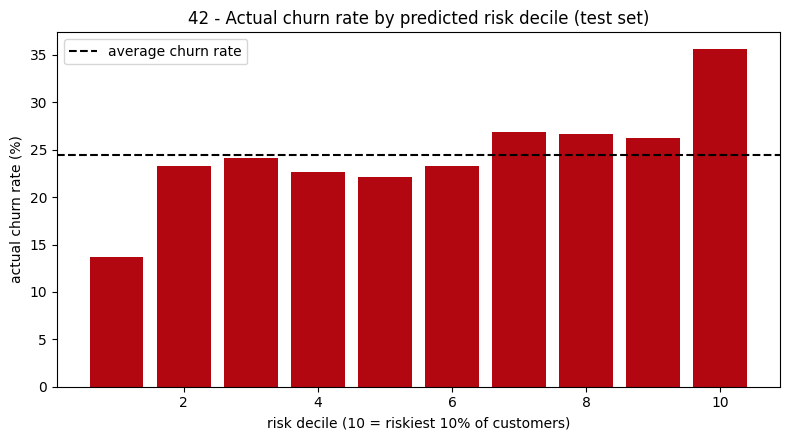


Contacting the riskiest 20%: 31.2% of them churn (average 24.5%), and we reach 25.6% of all churners.


In [9]:
# ---------- CELL 8: lift by risk decile ----------
result = pd.DataFrame({"customer_id": ids_test.values, "churn_probability": test_proba, "churned": y_test.values})
result["risk_decile"] = pd.qcut(result["churn_probability"].rank(method="first"), 10, labels=range(1, 11)).astype(int)   # 10 = riskiest

lift = (result.groupby("risk_decile")
              .agg(customers=("churned", "size"), churn_rate=("churned", "mean"))
              .assign(lift_vs_average=lambda t: t["churn_rate"] / result["churned"].mean())
              .round(3))
print(lift)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(lift.index, 100 * lift["churn_rate"], color="#b20710")
ax.axhline(100 * result["churned"].mean(), color="black", linestyle="--", label="average churn rate")
ax.set_xlabel("risk decile (10 = riskiest 10% of customers)"); ax.set_ylabel("actual churn rate (%)")
ax.set_title("42 - Actual churn rate by predicted risk decile (test set)"); ax.legend()
plt.tight_layout(); plt.savefig(FIGURES / "42_lift_by_decile.png", bbox_inches="tight"); plt.show()

top20 = result["churn_probability"] >= result["churn_probability"].quantile(0.80)
precision_top20 = result.loc[top20, "churned"].mean()
recall_top20 = result.loc[top20, "churned"].sum() / result["churned"].sum()
print(f"\nContacting the riskiest 20%: {100 * precision_top20:.1f}% of them churn (average {100 * y_test.mean():.1f}%), "
      f"and we reach {100 * recall_top20:.1f}% of all churners.")

avg_csat                   0.0318
minutes_90d                0.0121
tenure_days                0.0046
avg_rating                 0.0036
negative_feedback_share    0.0026
tickets_total              0.0025
auto_renew                 0.0020
tickets_365d               0.0016
payments_12m               0.0008
days_since_last_view       0.0008
sessions_90d               0.0007
age                        0.0005
dtype: float64


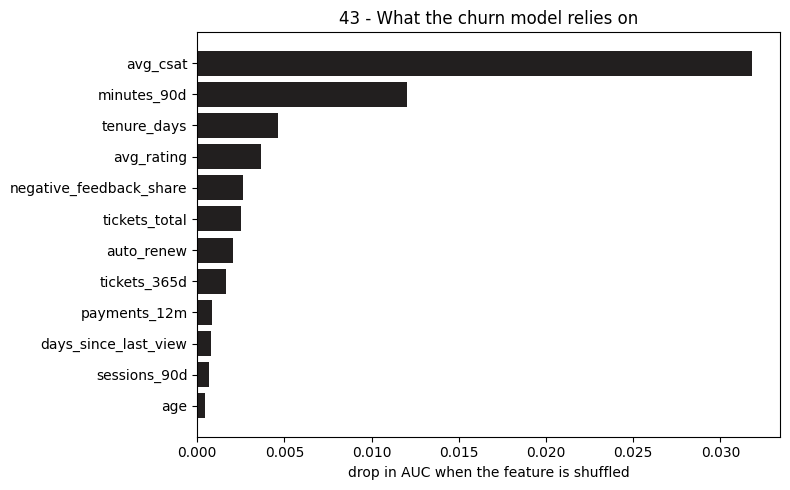

In [10]:
# ---------- CELL 9: feature importance ----------
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_pipeline, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
importance = (pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False))
print(importance.head(12).round(4))

top = importance.head(12).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="#221f1f")
plt.xlabel("drop in AUC when the feature is shuffled"); plt.title("43 - What the churn model relies on")
plt.tight_layout(); plt.savefig(FIGURES / "43_feature_importance.png", bbox_inches="tight"); plt.show()

In [11]:
# ---------- CELL 10: refit on everything and save ----------
final_model = clone(best_pipeline).fit(X, y)
MODELS.mkdir(exist_ok=True)
joblib.dump(final_model, MODELS / "churn_model.joblib")
print("saved:", (MODELS / "churn_model.joblib").relative_to(ROOT))

# reload to prove the saved file works
reloaded = joblib.load(MODELS / "churn_model.joblib")
assert np.allclose(reloaded.predict_proba(X.head(50))[:, 1], final_model.predict_proba(X.head(50))[:, 1])

saved: models/churn_model.joblib


In [12]:
# ---------- CELL 11: predictions for customers who are active on the as-of date ----------
active = scoring_table[scoring_table["active_at_snapshot"]].copy()
active["churn_probability"] = final_model.predict_proba(active[CATEGORICAL + NUMERIC])[:, 1].round(4)

active["risk_rank"] = active["churn_probability"].rank(method="first", ascending=False).astype(int)
share_from_top = 100 * active["risk_rank"] / len(active)                                  # 0.02 = the very riskiest customer, 100 = the safest
active["risk_percentile"] = share_from_top.round(1)                                       # for display
active["risk_tier"] = pd.cut(share_from_top, [0, 20, 50, 100], labels=["High", "Medium", "Low"])   # use the unrounded value so nobody falls outside the bins
assert active["risk_tier"].notna().all(), "some customers have no risk tier"

# plain-language reasons: simple rules based on the features, easy to explain to a manager
flag_rules = {
    "Failed payment (90d)":   active["failed_payments_90d"] > 0,
    "2+ support tickets":     active["tickets_365d"] >= 2,
    "Low support CSAT":       active["avg_csat"] <= 2.5,
    "Negative feedback":      active["negative_feedback_share"] >= 0.5,
    "Inactive 60+ days":      active["days_since_last_view"] >= 60,
    "Auto-renew off":         active["auto_renew"] == 0,
    "Under 1 year tenure":    active["tenure_days"] < 365,
}
flags = pd.DataFrame(flag_rules).fillna(False)
active["risk_flags"] = flags.apply(lambda row: ", ".join(row.index[row]), axis=1).replace("", "None")
active["flag_count"] = flags.sum(axis=1)

MODEL_OUT.mkdir(parents=True, exist_ok=True)
prediction_columns = ["customer_id", "snapshot_date", "churn_probability", "risk_rank", "risk_percentile",
                      "risk_tier", "flag_count", "risk_flags"]
active[prediction_columns].sort_values("risk_rank").to_csv(MODEL_OUT / "churn_predictions.csv", index=False)

print(len(active), "active customers scored")
print(active["risk_tier"].value_counts().to_dict())
active.sort_values("risk_rank")[["customer_id", "churn_probability", "risk_tier", "risk_flags"]].head(8)

6009 active customers scored
{'Low': 3005, 'Medium': 1803, 'High': 1201}


,customer_id,churn_probability,risk_tier,risk_flags
7257,CUST005732,0.5353,High,"Low support CSAT, Negative feedback, Auto-rene..."
5009,CUST005273,0.5205,High,"2+ support tickets, Under 1 year tenure"
4299,CUST007146,0.5036,High,"Low support CSAT, Under 1 year tenure"
3262,CUST007719,0.5027,High,"Failed payment (90d), Under 1 year tenure"
2321,CUST007481,0.5022,High,2+ support tickets
3704,CUST002536,0.5005,High,"2+ support tickets, Under 1 year tenure"
3054,CUST005435,0.4964,High,"Failed payment (90d), 2+ support tickets, Auto..."
4856,CUST006280,0.4910,High,Auto-renew off


In [13]:
# ---------- CELL 12: save evaluation files ----------
result.to_csv(MODEL_OUT / "churn_test_predictions.csv", index=False)

metrics = pd.concat([
    comparison.assign(stage="cross-validation (training data)"),
    pd.DataFrame([{"model": f"{best_name} (tuned)", "cv_auc_mean": round(search.best_score_, 3), "cv_auc_std": np.nan,
                   "stage": "cross-validation after tuning"},
                  {"model": f"{best_name} (final)", "cv_auc_mean": round(test_auc, 3), "cv_auc_std": np.nan,
                   "stage": "locked test set (AUC)"},
                  {"model": "Leaky version (do not use)", "cv_auc_mean": round(auc_leaky, 3), "cv_auc_std": np.nan,
                   "stage": "leakage demonstration"}]),
], ignore_index=True).rename(columns={"cv_auc_mean": "auc"})
metrics.to_csv(REPORTS / "churn_model_metrics.csv", index=False)
metrics

,model,auc,cv_auc_std,stage
0,Gradient Boosting,0.578,0.016,cross-validation (training data)
1,Logistic Regression,0.573,0.018,cross-validation (training data)
2,Random Forest,0.570,0.016,cross-validation (training data)
3,Baseline (always guess the average),0.500,0.000,cross-validation (training data)
4,Gradient Boosting (tuned),0.578,NaN,cross-validation after tuning
5,Gradient Boosting (final),0.568,NaN,locked test set (AUC)
6,Leaky version (do not use),0.648,NaN,leakage demonstration


In [14]:
# ---------- CELL 13: project log ----------
with open(DOCS / "project_log.md", "a") as f:
    f.write(f"""## Day 10 - Churn model
- Compared Logistic Regression, Random Forest and Gradient Boosting by 5-fold cross-validation. Chosen: {best_name}.
- Locked test set: AUC {test_auc:.3f}, average precision {test_ap:.3f}. Riskiest 20% churn at {100 * precision_top20:.1f}% (average {100 * y_test.mean():.1f}%).
- Leakage demo: honest AUC {search.best_score_:.3f} vs leaky {auc_leaky:.3f}.
- Saved models/churn_model.joblib and data/model_outputs/churn_predictions.csv ({len(active)} active customers).

""")
print("log updated")

log updated
